# Formative 3 — Probability Distributions, Bayesian Probability & Gradient Descent
### Group: 11

| Member | Part led |
|---|---|
| Milliam Mukamukiza | Part 1 (EM algorithm) |
| Dedine Mukabucyana | Part 2 (Bayesian probability) |
| Cedric Bigwi Hindura | Parts 3 & 4 (Gradient descent) |

*Mathematics for Machine Learning · ALU. All three members present every part. Code that is only set-up or plotting is collapsed (click the cell's left bar to expand); the algorithms themselves are always shown.*

In [1]:
import os, csv, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from src import presentation as pr
from src import gradient_descent as gd
from src.plotting import plot_lines

pr.set_style()
pd.options.display.float_format = "{:.4f}".format
GALTON_CSV = "GaltonFamilies.csv"
IMDB_CSV   = "IMDB Dataset.csv"      # download from the assignment link and place next to this notebook
FIG = "figures"; os.makedirs(FIG, exist_ok=True)

In [2]:
pr.banner("PART 1", "Probability Distributions — the EM algorithm", "Can a model discover two hidden height groups without being told who is who?", pr.BLUE)

**The problem.** We pool the heights of **mothers** (205, one per family) and **children** (934) and *delete the labels*. The pooled sample is a mixture of two bell curves, and **Expectation-Maximization (EM)** has to find them on its own. Labels come back only at the end, to grade the result.

In [3]:
# ============================================================
# PART 1: PROBABILITY DISTRIBUTIONS AND EM ALGORITHM
# Dataset: Galton Family Heights
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. LOAD AND PREPARE THE DATA
# ------------------------------------------------------------

data = pd.read_csv("GaltonFamilies.csv")

# One mother's height per family
mothers = data.drop_duplicates(subset="family")["mother"].to_numpy()

# All recorded children's heights
children = data["childHeight"].to_numpy()

# Combine heights to fit a two-component Gaussian mixture
heights = np.concatenate([mothers, children]).astype(float)

print("=" * 60)
print("PART 1: EM ALGORITHM")
print("=" * 60)
print("Number of families:", len(mothers))
print("Number of children:", len(children))
print("Total height observations:", len(heights))

PART 1: EM ALGORITHM
Number of families: 205
Number of children: 934
Total height observations: 1139


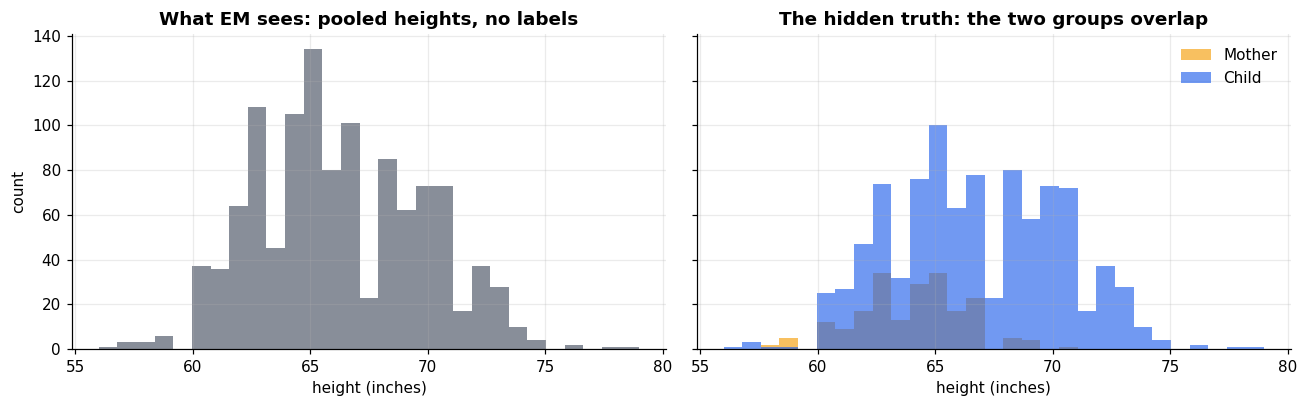

In [4]:
true_labels = np.concatenate([np.zeros(len(mothers), int), np.ones(len(children), int)])   # 0 = Mother, 1 = Child
pr.plot_data_overview(heights, true_labels)

In [5]:
pr.callout("Why this is hard", "On the right the two groups overlap a lot. No single height cleanly separates a mother from a child, so a good method must express <i>uncertainty</i>, not just draw a line.", pr.ORANGE)

### How EM works — two alternating steps
Model: $p(x)=\pi_1\,\mathcal N(x\mid\mu_1,\sigma_1^2)+\pi_2\,\mathcal N(x\mid\mu_2,\sigma_2^2)$

| Step | What it does | Formula |
|---|---|---|
| **Initialize** | Rough guess: means at the 25th/75th percentile, equal variances, $\pi=0.5$ each | — |
| **E-step** | Each height gets a *responsibility*: the probability it came from each component | $r_{ik}=\dfrac{\pi_k\mathcal N(x_i\mid\mu_k,\sigma_k^2)}{\sum_j \pi_j\mathcal N(x_i\mid\mu_j,\sigma_j^2)}$ |
| **M-step** | Re-estimate each component using responsibilities as weights ($N_k=\sum_i r_{ik}$) | $\mu_k=\frac{\sum_i r_{ik}x_i}{N_k},\ \ \sigma_k^2=\frac{\sum_i r_{ik}(x_i-\mu_k)^2}{N_k},\ \ \pi_k=\frac{N_k}{N}$ |
| **Stop** | When the log-likelihood barely changes | $\lvert \ln L_{t}-\ln L_{t-1}\rvert<10^{-6}$ |

#### Building blocks (Member 2's implementation)

In [6]:
# ------------------------------------------------------------
# 2. GAUSSIAN DISTRIBUTION FUNCTIONS
# ------------------------------------------------------------

def gaussian_log_pdf(x, mean, variance):
    """Return the log of a Gaussian probability density."""
    variance = max(variance, 1e-6)

    return -0.5 * (
        np.log(2 * np.pi * variance)
        + ((x - mean) ** 2) / variance
    )


def calculate_log_likelihood(x, means, variances, proportions):
    """Calculate the total log-likelihood of the mixture."""
    log_component_1 = (
        np.log(proportions[0])
        + gaussian_log_pdf(x, means[0], variances[0])
    )

    log_component_2 = (
        np.log(proportions[1])
        + gaussian_log_pdf(x, means[1], variances[1])
    )

    # Stable calculation of log(exp(a) + exp(b))
    maximum = np.maximum(log_component_1, log_component_2)

    log_total = maximum + np.log(
        np.exp(log_component_1 - maximum)
        + np.exp(log_component_2 - maximum)
    )

    return np.sum(log_total)

In [7]:
# ------------------------------------------------------------
# 3. INITIALIZE THE TWO GAUSSIAN COMPONENTS
# ------------------------------------------------------------

K = 2

# Start the means at the 25th and 75th percentiles
means = np.percentile(heights, [25, 75]).astype(float)

# Start both components with the same variance and weight
initial_variance = np.var(heights)
variances = np.array([initial_variance, initial_variance])

proportions = np.array([0.5, 0.5])

print("\nINITIAL PARAMETERS")
print("-" * 60)
print(f"Means: {means}")
print(f"Variances: {variances}")
print(f"Mixing proportions: {proportions}")
print(
    "Log-likelihood:",
    round(
        calculate_log_likelihood(
            heights, means, variances, proportions
        ),
        4,
    ),
)


INITIAL PARAMETERS
------------------------------------------------------------
Means: [63.5 69. ]
Variances: [12.58016036 12.58016036]
Mixing proportions: [0.5 0.5]
Log-likelihood: -3115.4014


#### E-step and M-step

In [8]:
# ------------------------------------------------------------
# 4. EXPECTATION STEP (E-STEP)
# ------------------------------------------------------------

def expectation_step(x, means, variances, proportions):
    """Calculate each observation's probability for each component."""

    log_prob_1 = (
        np.log(proportions[0])
        + gaussian_log_pdf(x, means[0], variances[0])
    )

    log_prob_2 = (
        np.log(proportions[1])
        + gaussian_log_pdf(x, means[1], variances[1])
    )

    maximum = np.maximum(log_prob_1, log_prob_2)

    prob_1 = np.exp(log_prob_1 - maximum)
    prob_2 = np.exp(log_prob_2 - maximum)

    total = prob_1 + prob_2

    responsibility_1 = prob_1 / total
    responsibility_2 = prob_2 / total

    return np.column_stack(
        (responsibility_1, responsibility_2)
    )

In [9]:
# ------------------------------------------------------------
# 5. MAXIMIZATION STEP (M-STEP)
# ------------------------------------------------------------

def maximization_step(x, responsibilities):
    """Update the means, variances and mixing proportions."""

    effective_counts = responsibilities.sum(axis=0)

    new_means = (
        responsibilities.T @ x
    ) / effective_counts

    new_variances = np.array([
        np.sum(
            responsibilities[:, k]
            * (x - new_means[k]) ** 2
        ) / effective_counts[k]
        for k in range(K)
    ])

    new_variances = np.maximum(new_variances, 1e-6)

    new_proportions = effective_counts / len(x)

    return new_means, new_variances, new_proportions

#### Running EM and recording the required tracking table

In [10]:
# ------------------------------------------------------------
# 6. RUN EM AND TRACK THE INITIAL STATE AND ITERATIONS 1 AND 2
# ------------------------------------------------------------

history = []

def save_state(iteration, means, variances, proportions):
    history.append({
        "Iteration": iteration,
        "Mean 1": means[0],
        "Mean 2": means[1],
        "Variance 1": variances[0],
        "Variance 2": variances[1],
        "Mixing proportion 1": proportions[0],
        "Mixing proportion 2": proportions[1],
        "Log-likelihood": calculate_log_likelihood(
            heights, means, variances, proportions
        ),
    })


save_state(0, means, variances, proportions)

previous_log_likelihood = calculate_log_likelihood(
    heights, means, variances, proportions
)

for iteration in range(1, 1001):

    # E-step: calculate probabilities using current parameters
    responsibilities = expectation_step(
        heights, means, variances, proportions
    )

    # M-step: update parameters
    new_means, new_variances, new_proportions = (
        maximization_step(heights, responsibilities)
    )

    means = new_means
    variances = new_variances
    proportions = new_proportions

    current_log_likelihood = calculate_log_likelihood(
        heights, means, variances, proportions
    )

    if iteration <= 2:
        save_state(iteration, means, variances, proportions)

    # Stop when the log-likelihood changes very little
    if abs(current_log_likelihood - previous_log_likelihood) < 1e-6:
        break

    previous_log_likelihood = current_log_likelihood


# Print the required tracking table
tracking_table = pd.DataFrame(history)

print("\nINITIAL STATE AND FIRST TWO EM ITERATIONS")
print(tracking_table.to_string(
    index=False,
    float_format=lambda value: f"{value:.4f}"
))

print("\nEM finished after", iteration, "iterations.")
print("FINAL PARAMETERS")
print("Means:", means)
print("Variances:", variances)
print("Mixing proportions:", proportions)
print(
    "Final log-likelihood:",
    round(
        calculate_log_likelihood(
            heights, means, variances, proportions
        ),
        4,
    ),
)


INITIAL STATE AND FIRST TWO EM ITERATIONS
 Iteration  Mean 1  Mean 2  Variance 1  Variance 2  Mixing proportion 1  Mixing proportion 2  Log-likelihood
         0 63.5000 69.0000     12.5802     12.5802               0.5000               0.5000      -3115.4014
         1 64.3037 68.2536      7.5712      9.8201               0.5067               0.4933      -3046.1412
         2 64.2587 68.3165      6.9517     10.0323               0.5087               0.4913      -3044.0230

EM finished after 386 iterations.
FINAL PARAMETERS
Means: [64.29928663 69.78556775]
Variances: [5.79348773 5.47469   ]
Mixing proportions: [0.64406188 0.35593812]
Final log-likelihood: -3035.7484


### Required tracking table — initial state and the first two iterations

In [11]:
tracking = tracking_table.rename(columns={"Mean 1": "μ1", "Mean 2": "μ2", "Variance 1": "σ1²", "Variance 2": "σ2²",
                                          "Mixing proportion 1": "π1", "Mixing proportion 2": "π2",
                                          "Log-likelihood": "Log-Likelihood"})
tracking.style.hide(axis="index").format("{:.4f}", subset=tracking.columns[1:]).background_gradient(
    subset=["Log-Likelihood"], cmap="Greens").set_caption("Component 1 = shorter group, component 2 = taller group")

Iteration,μ1,μ2,σ1²,σ2²,π1,π2,Log-Likelihood
0,63.5000,69.0000,12.5802,12.5802,0.5000,0.5000,-3115.4014
1,64.3037,68.2536,7.5712,9.8201,0.5067,0.4933,-3046.1412
2,64.2587,68.3165,6.9517,10.0323,0.5087,0.4913,-3044.0230


### Watching EM learn

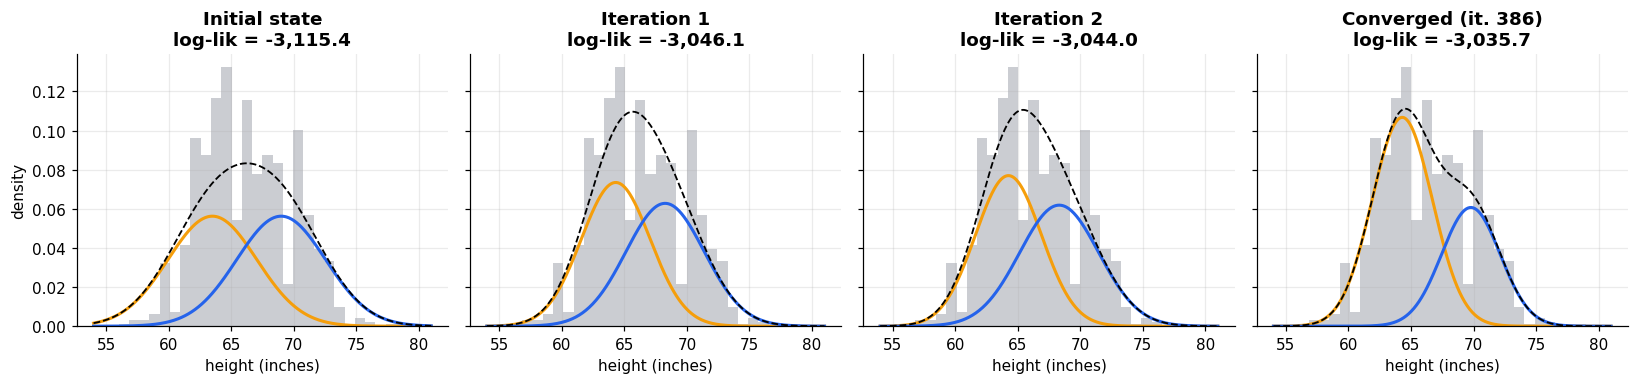

In [12]:
init = tracking_table.iloc[0]
hist = pr.run_em_history(heights, [init["Mean 1"], init["Mean 2"]], [init["Variance 1"], init["Variance 2"]],
                         [init["Mixing proportion 1"], init["Mixing proportion 2"]],
                         expectation_step, maximization_step, calculate_log_likelihood)
pr.plot_em_evolution(heights, hist)

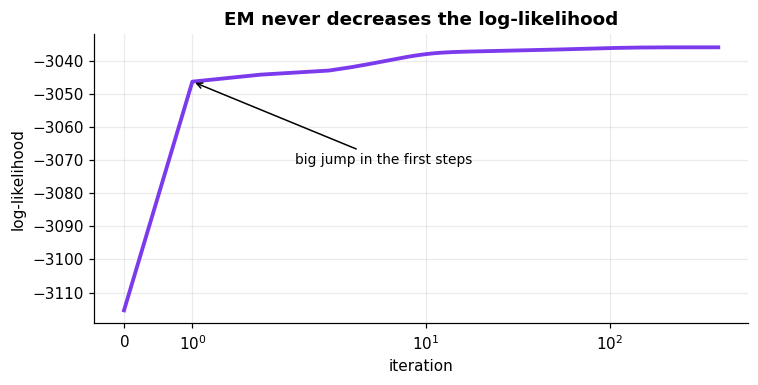

In [13]:
pr.plot_loglik(hist)

In [14]:
pr.callout("Stopping rule", f"The log-likelihood never decreases and flattens out. We stop when it changes by less than 1e-6 — here after <b>{len(hist)-1} iterations</b>, at log-likelihood <b>{hist[-1][3]:,.2f}</b>.", pr.PURPLE)

### Final fitted model and how well it matches the true groups

In [15]:
# ------------------------------------------------------------
# 7. POSTERIOR PROBABILITIES FOR A TEST HEIGHT
# ------------------------------------------------------------

test_height = 68.0

test_responsibilities = expectation_step(
    np.array([test_height]), means, variances, proportions
)[0]

print(f"\nPOSTERIOR PROBABILITIES FOR HEIGHT {test_height}")
print(f"Component 1: {test_responsibilities[0]:.4f}")
print(f"Component 2: {test_responsibilities[1]:.4f}")
print(
    "Probability total:",
    round(test_responsibilities.sum(), 4),
)


POSTERIOR PROBABILITIES FOR HEIGHT 68.0
Component 1: 0.4192
Component 2: 0.5808
Probability total: 1.0


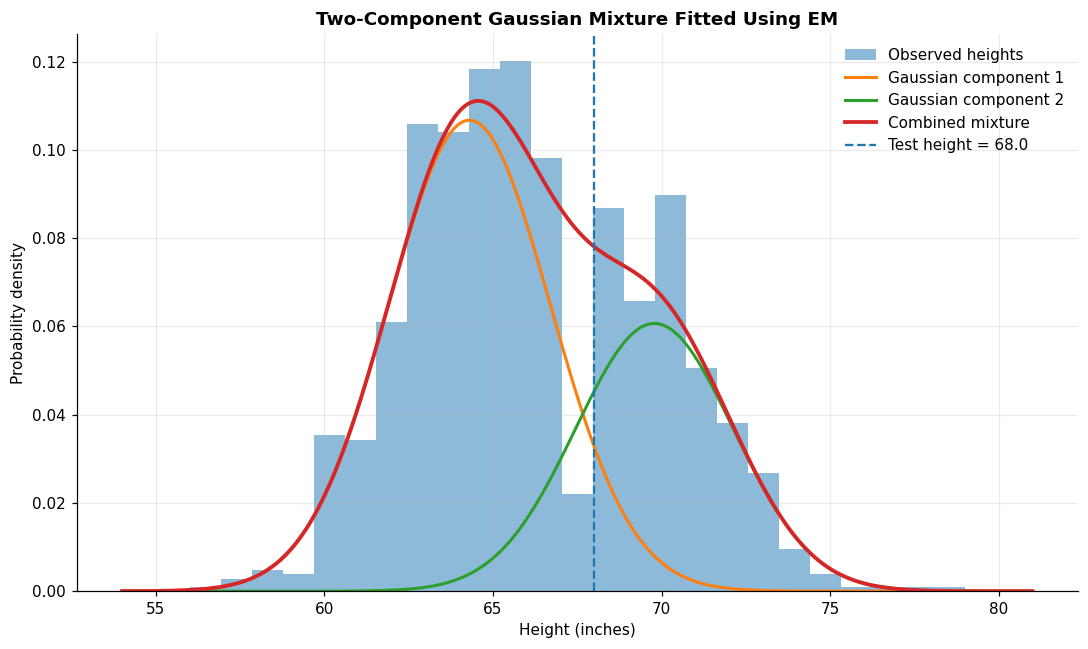

In [16]:
# ------------------------------------------------------------
# 8. GRAPH THE DATA AND THE TWO GAUSSIAN COMPONENTS
# ------------------------------------------------------------

x_grid = np.linspace(heights.min() - 2, heights.max() + 2, 500)

def gaussian_pdf(x, mean, variance):
    return np.exp(gaussian_log_pdf(x, mean, variance))


component_1 = proportions[0] * gaussian_pdf(
    x_grid, means[0], variances[0]
)

component_2 = proportions[1] * gaussian_pdf(
    x_grid, means[1], variances[1]
)

mixture_density = component_1 + component_2

plt.figure(figsize=(10, 6))

plt.hist(
    heights,
    bins=25,
    density=True,
    alpha=0.5,
    label="Observed heights",
)

plt.plot(
    x_grid,
    component_1,
    linewidth=2,
    label="Gaussian component 1",
)

plt.plot(
    x_grid,
    component_2,
    linewidth=2,
    label="Gaussian component 2",
)

plt.plot(
    x_grid,
    mixture_density,
    linewidth=2.5,
    label="Combined mixture",
)

plt.axvline(
    test_height,
    linestyle="--",
    label=f"Test height = {test_height}",
)

plt.xlabel("Height (inches)")
plt.ylabel("Probability density")
plt.title("Two-Component Gaussian Mixture Fitted Using EM")
plt.legend()
plt.tight_layout()
plt.savefig("part1_em_graph.png", dpi=300)
plt.show()

In [17]:
# ------------------------------------------------------------
# 10. EVALUATE EM COMPONENTS AGAINST THE KNOWN GROUP LABELS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MOTHER VS CHILD CLASSIFICATION EVALUATION")
print("=" * 60)

# The heights array was created with mothers first and children second.
actual_labels = np.concatenate([
    np.zeros(len(mothers), dtype=int),  # 0 = Mother
    np.ones(len(children), dtype=int),   # 1 = Child
])

# Get the most likely component for every observation.
all_responsibilities = expectation_step(
    heights, means, variances, proportions
)
predicted_components = np.argmax(all_responsibilities, axis=1)

# EM component numbers do not automatically mean Mother or Child.
# Test both possible mappings and select the one with more correct labels.
correct_if_component_1_is_mother = np.sum(
    (predicted_components == 0) == (actual_labels == 0)
)

correct_if_component_2_is_mother = np.sum(
    (predicted_components == 1) == (actual_labels == 0)
)

if correct_if_component_1_is_mother >= correct_if_component_2_is_mother:
    # Component 1 = Mother; Component 2 = Child
    predicted_labels = predicted_components.copy()
    mapping = "Component 1 = Mother; Component 2 = Child"
else:
    # Component 2 = Mother; Component 1 = Child
    predicted_labels = 1 - predicted_components
    mapping = "Component 2 = Mother; Component 1 = Child"

# Calculate the confusion matrix.
# Rows = actual labels; columns = predicted labels.
# Label 0 = Mother, Label 1 = Child.
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(actual_labels, predicted_labels):
    confusion_matrix[actual, predicted] += 1

true_mothers = confusion_matrix[0, 0]
mothers_predicted_as_children = confusion_matrix[0, 1]
children_predicted_as_mothers = confusion_matrix[1, 0]
true_children = confusion_matrix[1, 1]

accuracy = np.mean(actual_labels == predicted_labels)

print("Selected component mapping:", mapping)
print("\nConfusion matrix:")
print("Rows = actual group; columns = predicted group")
print("                    Predicted Mother  Predicted Child")
print(
    f"Actual Mother       {true_mothers:16d}"
    f"  {mothers_predicted_as_children:14d}"
)
print(
    f"Actual Child        {children_predicted_as_mothers:16d}"
    f"  {true_children:14d}"
)

print(f"\nCorrect predictions: {np.sum(actual_labels == predicted_labels)}")
print(f"Total observations: {len(actual_labels)}")
print(f"Classification accuracy: {accuracy * 100:.2f}%")

print("\nINTERPRETATION")
print(
    "The confusion matrix shows how many mothers and children "
    "were assigned to each predicted group."
)
print(
    "Accuracy is the percentage of all observations assigned "
    "to the correct group after choosing the better component mapping."
)
print(
    "This is an evaluation on the same observations used to fit EM, "
    "not a test of performance on new data."
)
print(
    "Because mother and child heights overlap and the children may "
    "be of different ages, height alone may not separate the groups well."
)
 


MOTHER VS CHILD CLASSIFICATION EVALUATION
Selected component mapping: Component 1 = Mother; Component 2 = Child

Confusion matrix:
Rows = actual group; columns = predicted group
                    Predicted Mother  Predicted Child
Actual Mother                    195              10
Actual Child                     545             389

Correct predictions: 584
Total observations: 1139
Classification accuracy: 51.27%

INTERPRETATION
The confusion matrix shows how many mothers and children were assigned to each predicted group.
Accuracy is the percentage of all observations assigned to the correct group after choosing the better component mapping.
This is an evaluation on the same observations used to fit EM, not a test of performance on new data.
Because mother and child heights overlap and the children may be of different ages, height alone may not separate the groups well.


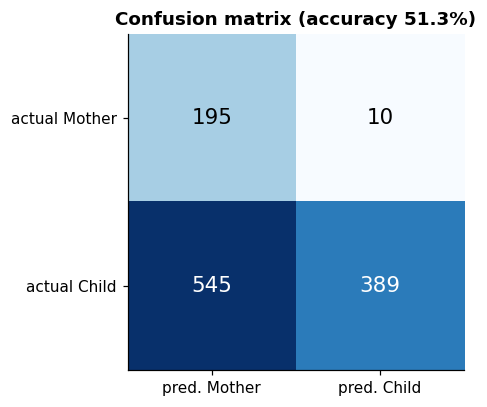

In [18]:
pr.plot_confusion(confusion_matrix, ['Mother', 'Child'], ['Mother', 'Child'], accuracy)

### Why not just split at the global mean and average each pile?

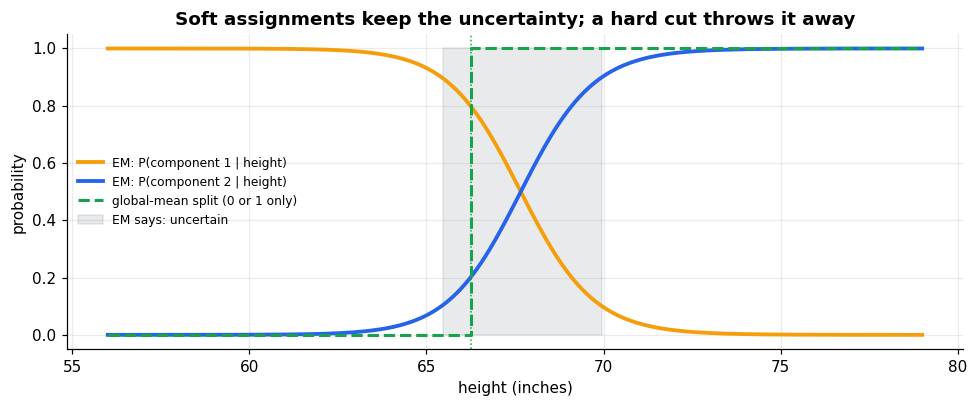

In [19]:
cut = heights.mean()
pr.plot_soft_vs_hard(heights, means, variances, proportions, cut, expectation_step)

In [20]:
low, high = heights[heights <= cut], heights[heights > cut]
split_means = np.array([low.mean(), high.mean()]); split_vars = np.array([low.var(), high.var()])
split_props = np.array([len(low), len(high)]) / len(heights)
pred_split = (heights > cut).astype(int)
acc_split = max(np.mean(pred_split == (true_labels == 1)), np.mean(pred_split != (true_labels == 1)))
comparison = pd.DataFrame({
    "global-mean split": [split_means[0], split_means[1], split_vars[0], split_vars[1], split_props[0], calculate_log_likelihood(heights, split_means, split_vars, split_props), acc_split],
    "EM":                [means[0], means[1], variances[0], variances[1], proportions[0], calculate_log_likelihood(heights, means, variances, proportions), accuracy]},
    index=["mean 1", "mean 2", "variance 1", "variance 2", "proportion 1", "log-likelihood", "accuracy vs mother/child"])
comparison.style.format("{:.4f}").highlight_max(axis=1, subset=pd.IndexSlice[["log-likelihood"], :], color="#bbf7d0")

,global-mean split,EM
mean 1,63.5759,64.2993
mean 2,69.4718,69.7856
variance 1,3.4783,5.7935
variance 2,4.5477,5.4747
proportion 1,0.5461,0.6441
log-likelihood,-3061.6755,-3035.7484
accuracy vs mother/child,0.5759,0.5127


In [21]:
pr.callout("Three reasons a mean-split fails",
  "<b>1. Overlap:</b> a hard line misclassifies everyone on the wrong side and can't say 'about 50/50'.<br>"
  "<b>2. Truncation:</b> chopping at a point cuts a tail off each pile, so pile variances come out too small (see table).<br>"
  "<b>3. Forced sizes:</b> the cut forces ~50/50 piles and ignores the true group sizes and spreads. "
  "EM learns means, variances <i>and</i> mixing proportions by maximising the likelihood, and gives soft probabilities instead of 0/1.", pr.GREEN)
pr.callout("Reading the numbers honestly",
  "EM wins on the objective it optimises (higher log-likelihood). But against the <i>mother/child</i> labels neither method does well: "
  "heights barely separate these groups, and the dominant structure is 'shorter vs taller', not 'mother vs child'. "
  "EM is a density model - it cannot know which cluster a human would name 'mothers'.", pr.ORANGE)

### Classifying a new height — posterior probabilities
**Change `TEST_HEIGHT` to the height the coach gives.** Component-to-label mapping is the one selected in the evaluation above.

Height = 68.0 in:   P(Mother) = 0.4192 (41.92%)    P(Child) = 0.5808 (58.08%)   ->  Child


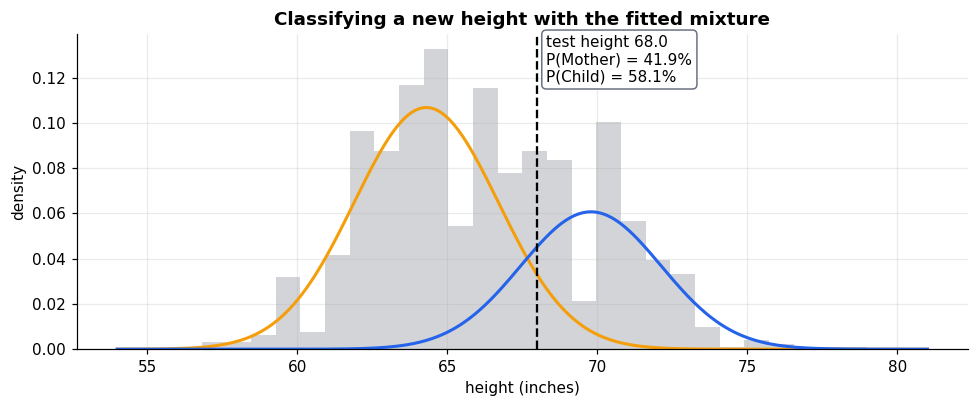

In [22]:
mother_component = 0 if mapping.startswith("Component 1 = Mother") else 1
child_component = 1 - mother_component

def classify(height):
    r = expectation_step(np.array([float(height)]), means, variances, proportions)[0]
    p_mother, p_child = r[mother_component], r[child_component]
    print(f"Height = {height} in:   P(Mother) = {p_mother:.4f} ({p_mother:.2%})    P(Child) = {p_child:.4f} ({p_child:.2%})"
          f"   ->  {'Mother' if p_mother > p_child else 'Child'}")
    return p_mother, p_child

TEST_HEIGHT = 68.0
p_m, p_c = classify(TEST_HEIGHT)
m_order = [mother_component, child_component]
pr.plot_test_height(heights, means, variances, proportions, TEST_HEIGHT, p_m, p_c)

In [23]:
pr.banner("PART 2", "Bayesian Probability — IMDb movie reviews", "How much does seeing one word change our belief that a review is positive?", pr.GREEN)

**Our choice:** We calculate **P(Positive | keyword)** only, not P(Negative | keyword).

**Dataset:** 50,000 IMDb reviews, half positive and half negative, so the prior P(Positive) = 0.5.

**Method (basic Python only):** For each keyword we compute
- **Prior:** positive reviews / all reviews
- **Likelihood:** positive reviews with the word / positive reviews
- **Marginal:** reviews with the word / all reviews
- **Posterior:** Likelihood x Prior / Marginal (Bayes' theorem)

**Keywords and why:**
- **Positive:** excellent, wonderful, amazing (direct praise) and great (very common, so we test if a popular word is also reliable).
- **Negative:** terrible, awful (direct criticism), boring (a common reason for a bad review) and worst (used in extreme complaints).

> $$P(\text{Positive}\mid w)=\frac{P(w\mid\text{Positive})\;P(\text{Positive})}{P(w)}$$

In [24]:
import csv
import re

def load(path):
    reviews = []
    with open(path, encoding="utf-8") as f:
        rows = csv.reader(f)
        next(rows)  # skip the header
        for text, label in rows:
            words = set(re.findall(r"[a-z']+", text.lower()))
            reviews.append((words, label))
    return reviews

reviews = load(IMDB_CSV)
print(len(reviews), "reviews loaded")

50000 reviews loaded


#### Bayes' theorem in code (Member 1's implementation, basic Python only)

In [25]:
def bayes(reviews, word):
    total = len(reviews)
    pos = sum(1 for words, label in reviews if label == "positive")
    has = sum(1 for words, label in reviews if word in words)
    has_pos = sum(1 for words, label in reviews if word in words and label == "positive")

    prior = pos / total                         # P(Positive)
    likelihood = has_pos / pos                  # P(word | Positive)
    marginal = has / total                      # P(word)
    posterior = likelihood * prior / marginal   # Bayes' theorem
    return prior, likelihood, marginal, posterior

#### The required table: prior, likelihood, marginal, posterior for every keyword

In [26]:
keywords = ["excellent", "wonderful", "amazing", "great",
            "terrible", "awful", "boring", "worst"]

print(f"{'word':<11}{'prior':>7}{'likelihood':>12}{'marginal':>10}{'posterior':>11}")
for word in keywords:
    prior, likelihood, marginal, posterior = bayes(reviews, word)
    print(f"{word:<11}{prior:>7.4f}{likelihood:>12.4f}{marginal:>10.4f}{posterior:>11.4f}")

word         prior  likelihood  marginal  posterior
excellent   0.5000      0.1146    0.0710     0.8073
wonderful   0.5000      0.0902    0.0555     0.8120
amazing     0.5000      0.0671    0.0431     0.7783
great       0.5000      0.3387    0.2512     0.6741
terrible    0.5000      0.0152    0.0539     0.1413
awful       0.5000      0.0112    0.0575     0.0977
boring      0.5000      0.0236    0.0610     0.1938
worst       0.5000      0.0164    0.0886     0.0924


In [27]:
prior, likelihood, marginal, posterior = bayes(reviews, "worst")
pr.bayes_card("worst", prior, likelihood, marginal, posterior)

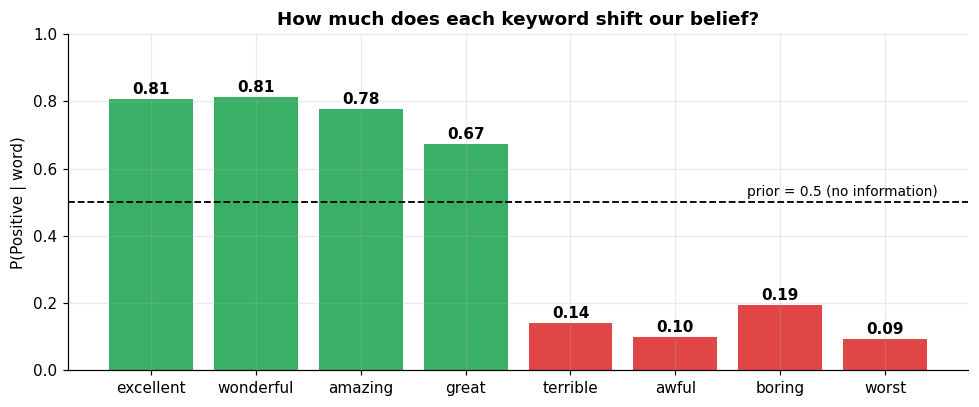

In [28]:
pr.plot_posteriors(keywords, [bayes(reviews, w)[3] for w in keywords], n_pos=4)

## What our results show
- **wonderful (0.81)** and **excellent (0.81)** are our strongest positive signals.
- **worst (0.09)** and **awful (0.10)** are our strongest negative signals. A review containing "worst" is only about 9% likely to be positive.
- **great (0.67)** is our weakest positive word. It appears in about 25% of all reviews, including many negative ones, so it is a weaker clue than its popularity suggests.
- All four positive keywords have a posterior above the 0.5 prior, and all four negative keywords have a posterior far below it. This supports our keyword choices.

In [29]:
pr.banner("PARTS 3 & 4", "Gradient Descent — by hand, then in code with SciPy", "How does a model improve its predictions step by step?", pr.PURPLE)

## Part 3 — Manual calculation

The full handwritten-style derivation is in **`docs/Part3_Manual_Calculations.pdf`**. Here we restate the set-up and *check every manual number with matrix code*.

**Model:** $\hat y = Xm + b$, with $X=\begin{pmatrix}1&3\\4&10\end{pmatrix}$, $y=\begin{pmatrix}5\\6\end{pmatrix}$, $m_0=\begin{pmatrix}-1\\2\end{pmatrix}$, $b_0=\begin{pmatrix}1\\1\end{pmatrix}$.

**Cost:** $J(m,b)=\frac1n(\hat y-y)^\top(\hat y-y)$, $n=2$.

**Chain rule.** Let $u=\hat y-y$, so $J=\frac1n u^\top u$:
$$\frac{\partial J}{\partial u}=\frac{2}{n}u,\qquad \frac{\partial u}{\partial m}=X,\qquad \frac{\partial u}{\partial b}=I
\;\Rightarrow\;
\boxed{\frac{\partial J}{\partial m}=\frac2n X^\top(\hat y-y)},\quad
\boxed{\frac{\partial J}{\partial b}=\frac2n(\hat y-y)}$$

**Update rule:** $m\leftarrow m-\alpha\,\partial J/\partial m$, $\;b\leftarrow b-\alpha\,\partial J/\partial b$ with learning rate $\alpha=0.01$.

**Assumptions we state explicitly** (the brief leaves them open):
* $b=[1,1]^\top$ is treated as a **vector, one bias entry per data point** (so it is a matrix quantity, not a scalar).
* $\alpha=0.01$. Larger values diverge here: the largest eigenvalue of the Hessian is ≈ 127, which requires $\alpha<2/127\approx0.0157$.
* Number of updates = number of group members.

In [30]:
N_MEMBERS = 3        # one gradient-descent update per group member
LR = 0.01
X  = np.array([[1., 3.], [4., 10.]])
y  = np.array([5., 6.])
m0 = np.array([-1., 2.])
b0 = np.array([1., 1.])

**The three hand-calculated updates (one per member) are in `docs/Part3_Manual_Calculations.pdf` and will be demonstrated live during the presentation.** Part 4 below reproduces the same three updates in code so the numbers can be compared line by line.

**Trend.** After each update the cost $J$ falls (61 → 6.50 → 2.50 → 2.16 → …) and the parameters move in the direction of the *negative* gradient, so **yes — the updates reduce the error**. The first step is large because the initial gradient is large (≈45 and ≈113 for $m$); later steps shrink as the gradient flattens. $m_1$ becomes more negative and $m_2$ drops from 2 to about 1.1 — they have not converged yet, but the error is already close to its slowly-decreasing tail.

## Part 4 — Gradient descent in code (SciPy)

### 4.1 A function that accepts an equation and returns its derivative (SciPy)
`gd.partial_derivative(f, theta, i)` takes **any equation `f` of a parameter vector** and uses `scipy.differentiate.derivative` to get ∂f/∂θᵢ. `gd.scipy_gradient` stacks these into the gradient. First a sanity check on a function whose derivative we know:

In [31]:
f = lambda t: t[0] ** 3 + 2 * t[0] * t[1] ** 2          # f(x, y) = x^3 + 2xy^2
theta = np.array([2.0, 3.0])
print("SciPy  gradient:", np.round(gd.scipy_gradient(f, theta), 6))
print("Exact  gradient: [3x^2 + 2y^2, 4xy] =", [3 * 2**2 + 2 * 3**2, 4 * 2 * 3])

SciPy  gradient: [30. 24.]
Exact  gradient: [3x^2 + 2y^2, 4xy] = [30, 24]


Now check the SciPy gradient of our MSE cost against the analytic chain-rule formula from Part 3:

In [32]:
g_scipy = gd.scipy_gradient(lambda t: gd.cost_of_theta(t, X, y), gd.pack(m0, b0))
dm_a, db_a = gd.analytic_gradients(X, m0, b0, y)
print("SciPy    [dm, db]:", np.round(g_scipy, 6))
print("Analytic [dm, db]:", np.round(np.concatenate([dm_a, db_a]), 6))
assert np.allclose(g_scipy, np.concatenate([dm_a, db_a]), atol=1e-6)

SciPy    [dm, db]: [ 45. 113.   1.  11.]
Analytic [dm, db]: [ 45. 113.   1.  11.]


### 4.2 Every calculation step visible
The cell below does **not** hide anything inside a helper: predictions → error → cost → SciPy gradients → updates, printed for the first `N_MEMBERS` iterations.

In [33]:
m, b = m0.copy(), b0.copy()
for it in range(1, N_MEMBERS + 1):
    y_hat = X @ m + b                                              # predictions
    error = y_hat - y                                              # residuals
    cost  = error @ error / len(y)                                 # MSE
    grad  = gd.scipy_gradient(lambda t: gd.cost_of_theta(t, X, y), gd.pack(m, b))   # SciPy derivatives
    dm, db = grad[:2], grad[2:]
    m_new, b_new = m - LR * dm, b - LR * db                        # updates
    print(f"iter {it}: y_hat={np.round(y_hat,4)} J={cost:.4f} dm={np.round(dm,4)} db={np.round(db,4)}")
    print(f"        m: {np.round(m,4)} -> {np.round(m_new,4)}    b: {np.round(b,4)} -> {np.round(b_new,4)}")
    m, b = m_new, b_new

iter 1: y_hat=[ 6. 17.] J=61.0000 dm=[ 45. 113.] db=[ 1. 11.]
        m: [-1.  2.] -> [-1.45  0.87]    b: [1. 1.] -> [0.99 0.89]
iter 2: y_hat=[2.15 3.79] J=6.5033 dm=[-11.69 -30.65] db=[-2.85 -2.21]
        m: [-1.45  0.87] -> [-1.3331  1.1765]    b: [0.99 0.89] -> [1.0185 0.9121]
iter 3: y_hat=[3.2149 7.3447] J=2.4974 dm=[3.5937 8.0917] db=[-1.7851  1.3447]
        m: [-1.3331  1.1765] -> [-1.369   1.0956]    b: [1.0185 0.9121] -> [1.0364 0.8987]


### 4.3 Run to (near) convergence and plot

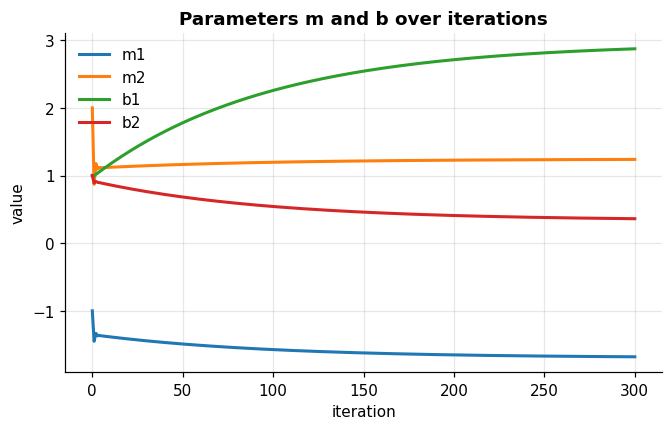

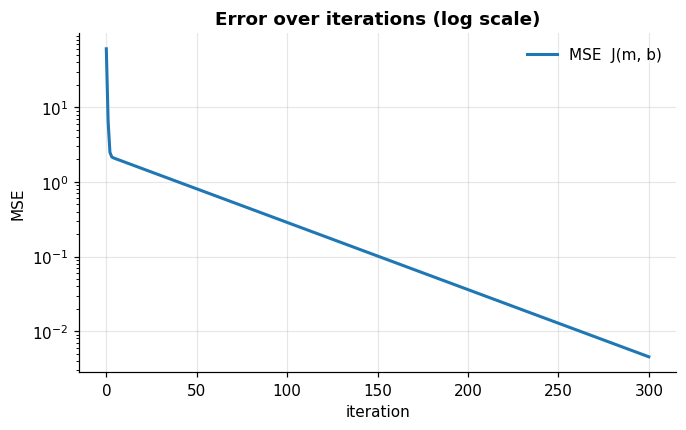

In [34]:
N_ITER = 300
m_fin, b_fin, hist = gd.run_gradient_descent(X, y, m0, b0, LR, N_ITER)
its = [h["iteration"] for h in hist]
M = np.array([h["m"] for h in hist]); B = np.array([h["b"] for h in hist]); J = [h["cost"] for h in hist]

plot_lines(its, {"m1": M[:, 0], "m2": M[:, 1], "b1": B[:, 0], "b2": B[:, 1]},
           "Parameters m and b over iterations", "iteration", "value", path=f"{FIG}/gd_parameters.png"); plt.show()
plot_lines(its, {"MSE  J(m, b)": J}, "Error over iterations (log scale)", "iteration", "MSE", path=f"{FIG}/gd_error.png", logy=True); plt.show()

#### The model's predictions improve

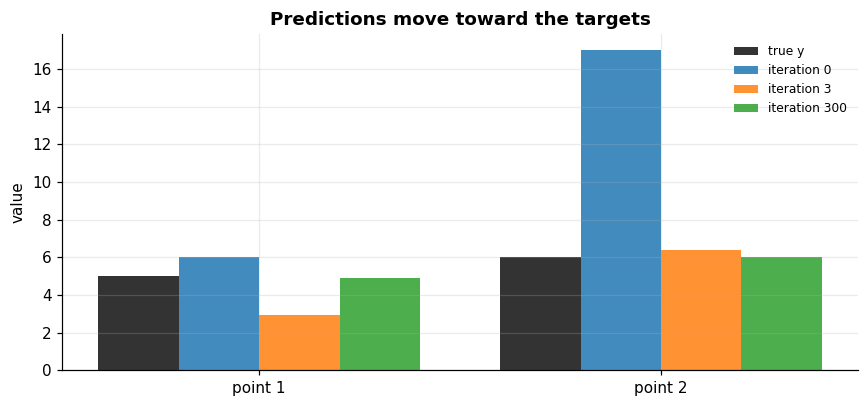

In [35]:
pr.plot_predictions(y, [(f"iteration {t}", hist[t]["y_hat"]) for t in (0, 3, len(hist) - 1)])

In [36]:
pr.callout("Trend", f"Error falls from <b>{J[0]:.1f}</b> to <b>{J[3]:.2f}</b> after the three hand-calculated updates and to <b>{J[-1]:.4f}</b> after {N_ITER}: the parameters move against the gradient, so every step reduces the error.", pr.GREEN)

### 4.4 Predictions with the final m and b

In [37]:
y_pred = gd.predict(X, m_fin, b_fin)
print("final m =", np.round(m_fin, 4), "  final b =", np.round(b_fin, 4))
pd.DataFrame({"x": [tuple(r) for r in X], "y (true)": y, "y_hat (final)": y_pred, "error": y_pred - y})

final m = [-1.6794  1.2382]   final b = [2.8734 0.3618]


,x,y (true),y_hat (final),error
0,"(1.0, 3.0)",5.0000,4.9087,-0.0913
1,"(4.0, 10.0)",6.0000,6.0268,0.0268


In [38]:
print(f"Final MSE after {N_ITER} iterations: {J[-1]:.6f}  (started at {J[0]:.1f})")

Final MSE after 300 iterations: 0.004522  (started at 61.0)


---
**Reproduce:** `pip install -r requirements.txt`, put `GaltonFamilies.csv` and `IMDB Dataset.csv` next to this notebook, then *Restart & Run All*.